# Set Up Environment (Local Version)

This is a local-Jupyter version of the Colab notebook.

**One-time setup**, done already if you used VS Code's "Quick Create venv" environment manager (it creates `.venv` in the repo root and installs `requirements.txt` for you). If you ever need to do it by hand instead, from a terminal in the repo root:
```powershell
py -m venv .venv
.\.venv\Scripts\Activate.ps1
pip install -r requirements.txt
```
Either way, open this notebook in VS Code, click the kernel picker in the top right, and select the **.venv** interpreter for this workspace — no manual `ipykernel install` step needed, VS Code handles that automatically once `.venv` is selected.


In [1]:
# Sanity check: confirm the notebook is using the venv's Python, and that we're in the repo root
import sys, os
print('Python executable:', sys.executable)
print('Working directory:', os.getcwd())
# If the working directory isn't the repo root, uncomment and adjust:
# %cd /path/to/hamiltonian-nn


Python executable: c:\Users\lukis\Documents\GitHub\hamiltonian-nn\.venv\Scripts\python.exe
Working directory: c:\Users\lukis\Documents\GitHub\hamiltonian-nn


# Creating Dataset and Training Models


## Dataset


In [4]:
# Creates dataset for model training and visualization
# (uses the parallelized sample_orbits -- pass num_workers=N to data3dcanonical.make_orbits_dataset
#  if you ever want to call it directly from a cell instead of via the script)
!{sys.executable} experiment-3body/3D/make_3d_dataset.py


^C


python experiment-3body/3D/make_3d_dataset.py # Type this in powershell for project bar

In [2]:
# Displays the dataset
!{sys.executable} experiment-3body/3D/show_3d_dataset.py


{'coords': array([[ 0.52069827,  0.33785932, -0.76376981, ...,  0.44136195,
         0.02532551, -0.66898826],
       [ 0.41201774,  0.40496066, -0.93589139, ...,  0.37777836,
         0.43158697, -0.66680502],
       [ 0.21905539,  0.38441446, -1.10751401, ...,  0.16208735,
         0.94776981, -0.6570053 ],
       ...,
       [-1.02588189, -0.88173744, -2.71767972, ...,  0.49786229,
         0.74920612, -0.4209851 ],
       [-1.26277808, -0.73629472, -2.81984243, ...,  0.48054381,
         0.73488944, -0.42206449],
       [-1.27289248, -1.08121247, -2.97649208, ...,  0.46544329,
         0.72200008, -0.42300049]], shape=(80000, 18)), 'test_coords': array([[ 0.94378445,  0.02844251,  0.38945343, ...,  0.49114248,
        -0.3040624 ,  0.29773736],
       [ 0.91526674,  0.1920245 ,  0.46011571, ...,  0.55862197,
        -0.146985  ,  0.29784559],
       [ 0.84215451,  0.34652887,  0.53121002, ...,  0.59841577,
         0.02546223,  0.29821452],
       ...,
       [-1.168416  ,  0.22394

## Training


In [ ]:
!{sys.executable} experiment-3body/3D/train3DtestcodeTesting.py --verbose



# Visualizations


In [2]:
# runs script for visualization
%matplotlib widget
# If ipympl/widget still misbehaves locally, fall back to:
# %matplotlib inline
%run experiment-3body/3D/visuals3dcanonical.py

# Restart the kernel if the line above doesn't work, then re-run the sanity-check cell first


## Ground truth


canonical kaka


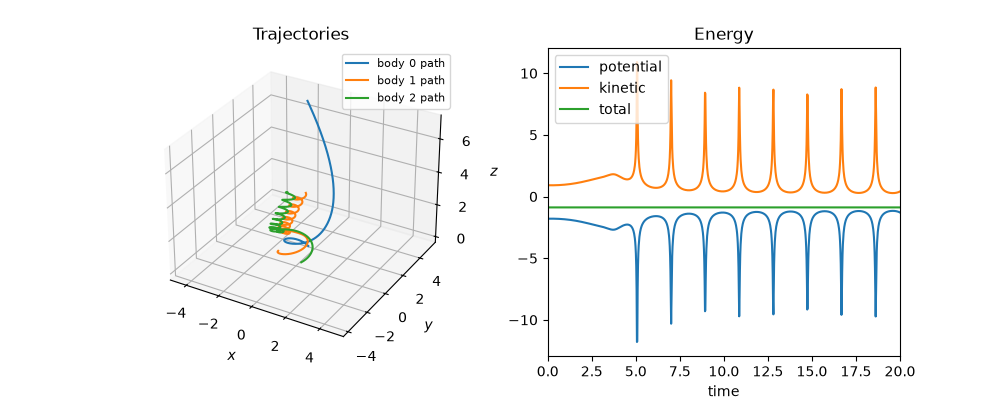

In [4]:
# displays orbits from dataset
plot_ground_truth(plot3d=True)


## Basline Model


In [ ]:
# Loads baseline and hnn models (models need to be trained first before visualizations related to models can be displayed)

def load_model(args, baseline=False):
    output_dim = args.input_dim if baseline else 1
    nn_model = MLP(args.input_dim, args.hidden_dim, output_dim, args.nonlinearity)
    model = HNN(args.input_dim, differentiable_model=nn_model,
            field_type=args.field_type, baseline=baseline)
    case = 'baseline' if baseline else 'hnn'
    path = "{}/{}-orbits-{}.tar".format(args.save_dir, args.name, case)
    print(path)
    model.load_state_dict(torch.load(path))
    return model

args = ObjectView(get_args())
base_model = load_model(args, baseline=True)
hnn_model = load_model(args, baseline=False)


In [ ]:
what_has_baseline_learned(base_model, args)


## HNN Model


In [ ]:
what_has_hnn_learned(hnn_model, args)


## All orbits


In [ ]:
visualize_all_orbits(base_model, hnn_model, args)


## Energies


In [ ]:
visualize_all_energies(base_model, hnn_model, args)


## Energy Conservation


In [ ]:
visualize_energy_conservation(base_model, hnn_model, args)


## Training Curves


In [ ]:
plot_training_curves()


# 2D



In [ ]:
# Creates dataset for model training and visualization
!{sys.executable} experiment-3body/2D/make_dataset.py


In [ ]:
# Prints dataset and gives info regarding each feature
!{sys.executable} experiment-3body/2D/show_dataset.py


In [ ]:
!{sys.executable} experiment-3body/2D/train.py --verbose


In [ ]:
%run experiment-3body/2D/visuals.py


In [ ]:
# Loads baseline and hnn models (models need to be trained first before visualizations related to models can be displayed)

def load_model(args, baseline=False):
    output_dim = args.input_dim if baseline else 2
    nn_model = MLP(args.input_dim, args.hidden_dim, output_dim, args.nonlinearity)
    model = HNN(args.input_dim, differentiable_model=nn_model,
            field_type=args.field_type, baseline=baseline)
    case = 'baseline' if baseline else 'hnn'
    path = "{}/{}-orbits-{}.tar".format(args.save_dir, args.name, case)
    print(path)
    model.load_state_dict(torch.load(path))
    return model

args = ObjectView(get_args())
base_model = load_model(args, baseline=True)
hnn_model = load_model(args, baseline=False)


In [ ]:
plot_ground_truth()


In [ ]:
what_has_baseline_learned(base_model, args)


In [ ]:
what_has_hnn_learned(hnn_model, args)
